In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("msambare/fer2013")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'fer2013' dataset.
Path to dataset files: /kaggle/input/fer2013


In [2]:
import os
import cv2
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

In [3]:
# Dataset path
train_path = r"/kaggle/input/fer2013/train"
test_path  = r"/kaggle/input/fer2013/test"

In [4]:
# Emotion labels (IMPORTANT: match folder names order)
labels = ['angry','happy','sad','surprise','neutral']

In [5]:
# Load images manually
def load_data(path):
    X, y = [], []

    for label_index, label in enumerate(labels):
        folder_path = os.path.join(path, label)

        for img_name in os.listdir(folder_path):
            img_path = os.path.join(folder_path, img_name)

            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
            img = cv2.resize(img, (48, 48))

            X.append(img)
            y.append(label_index)

    return np.array(X), np.array(y)   # Convert to numpy

# Use it
X, y = load_data(train_path)
X_test, y_test = load_data(test_path)

In [6]:
X.dtype,X_test.dtype

(dtype('uint8'), dtype('uint8'))

In [7]:
'''
convert values into float type for normalization
'''
X=X.astype('float32')
X_test=X_test.astype('float32')

In [8]:
X.shape,y.shape

((24176, 48, 48), (24176,))

In [9]:
X_test.shape,y_test.shape

((6043, 48, 48), (6043,))

In [10]:
# Normalize
X = X / 255.0
X_test= X_test/ 255.0

In [11]:
# Reshape for CNN
X = X.reshape(-1, 48, 48, 1)
X_test= X_test.reshape(-1, 48, 48, 1)

In [12]:
# One-hot encoding
y = to_categorical(y)
y_test=to_categorical(y_test)

In [13]:
# Train-test split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2)

In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Dropout, Flatten

model = Sequential()

model.add(Conv2D(32, (3,3), activation='relu', input_shape=(48,48,1)))
model.add(MaxPooling2D(2,2))

model.add(Conv2D(64, (3,3), activation='relu'))
model.add(MaxPooling2D(2,2))

model.add(Conv2D(128, (3,3), activation='relu'))
model.add(MaxPooling2D(2,2))

model.add(Flatten())

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(5, activation='softmax'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [17]:
model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 46, 46, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 355,589 (1.36 MB)

 Trainable params: 355,589 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
history = model.fit(X_train, y_train,epochs=10,batch_size=64,validation_data=(X_test,y_test))

Epoch 1/10
303/303 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.3389 - loss: 1.5124 - val_accuracy: 0.4584 - val_loss: 1.3511
Epoch 2/10
303/303 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4604 - loss: 1.2993 - val_accuracy: 0.5103 - val_loss: 1.1960
Epoch 3/10
303/303 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5222 - loss: 1.1787 - val_accuracy: 0.5590 - val_loss: 1.0921
Epoch 4/10
303/303 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5589 - loss: 1.1000 - val_accuracy: 0.5775 - val_loss: 1.0425
Epoch 5/10
303/303 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.5846 - loss: 1.0459 - val_accuracy: 0.5820 - val_loss: 1.0376
Epoch 6/10
303/303 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6042 - loss: 1.0035 - val_accuracy: 0.6037 - val_loss: 0.9860
Epoch 7/10
303/303 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6237 - loss: 0.9553 - val_accuracy: 0.6144 - val_loss: 0.9561
Epoch 8/10
303/303 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6400 - loss: 0.9241 - val_accuracy: 

In [19]:
test_loss,test_acc=model.evaluate(X_test,y_test)
print(test_loss,test_acc)

189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6328 - loss: 0.9334
0.9334043264389038 0.6327982544898987


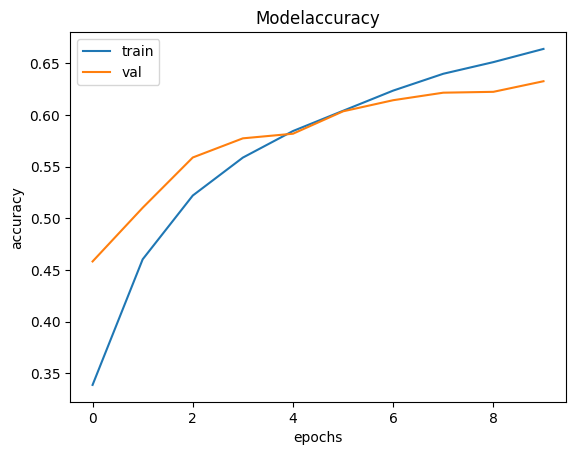

In [20]:
#ploting the history of validation
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Modelaccuracy')
plt.xlabel('epochs')
plt.ylabel('accuracy')
plt.legend(['train','val'],loc='upper left')
plt.show()

In [21]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

print(classification_report(y_true, y_pred_classes))

189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
              precision    recall  f1-score   support

           0       0.57      0.44      0.50       958
           1       0.76      0.80      0.78      1774
           2       0.51      0.48      0.49      1247
           3       0.76      0.78      0.77       831
           4       0.53      0.59      0.56      1233

    accuracy                           0.63      6043
   macro avg       0.62      0.62      0.62      6043
weighted avg       0.63      0.63      0.63      6043



In [22]:
from sklearn.metrics import confusion_matrix

print("Confusion_matrix:\n",confusion_matrix(y_true, y_pred_classes))


Confusion_matrix:
 [[ 421  109  209   54  165]
 [  82 1426  100   49  117]
 [ 122  144  601   53  327]
 [  32   65   40  651   43]
 [  86  139  236   47  725]]
